# 04 · Revisão da equipe

Este notebook resume as decisões que exigem validação humana sobre os artefatos finais da versão v1.1. Ele não reconfigura nem republica modelos: seu papel é tornar as evidências, ressalvas e alertas investigáveis pela equipe.

**Roteiro:** aprovar decisões do protocolo → validar nomes e transições dos regimes → priorizar alertas para parecer operacional.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Raiz do projeto não encontrada.")


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

from regime_anomaly import modeling as md
from regime_anomaly import preprocessing as pp
from regime_anomaly.config import IMAGES_DIR, METADATA_DIR, PROCESSED_DIR, TABLES_DIR

HIGH_CONTRAST_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
REGIME_COLORS = dict(zip(md.REGIME_NAMES, HIGH_CONTRAST_PALETTE[:3]))
sns.set_theme(style="whitegrid", palette=HIGH_CONTRAST_PALETTE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)
RECURRENCE_MIN_WEEKS = 3
LEADING_ON_KVARH = 1.0
LOW_LOAD_KWH = 10.0


def save_figure(fig, name: str) -> None:
    fig.savefig(IMAGES_DIR / name, dpi=150, bbox_inches="tight")


def save_table(frame: pd.DataFrame, name: str, index: bool = True) -> None:
    frame.to_csv(TABLES_DIR / name, index=index, encoding="utf-8-sig")


metrics = json.loads((METADATA_DIR / "final_metrics.json").read_text(encoding="utf-8"))
results = pd.read_csv(PROCESSED_DIR / "analysis_results.csv", parse_dates=[pp.TIMESTAMP_COLUMN])
results = results.sort_values(pp.TIMESTAMP_COLUMN).reset_index(drop=True)
results["inicio"] = results[pp.TIMESTAMP_COLUMN] - pp.EXPECTED_FREQUENCY
results["hora"] = results["inicio"].dt.hour
results["intervalo"] = (
    results["inicio"].dt.strftime("%H:%M") + "–" + results[pp.TIMESTAMP_COLUMN].dt.strftime("%H:%M")
)
# Semana corrida desde o início da série (a semana ISO juntaria 31/12 com a semana 1).
first_day = results["inicio"].dt.normalize().min()
results["semana"] = (results["inicio"].dt.normalize() - first_day).dt.days // 7
print(
    f"{len(results):,} leituras · modelo {metrics['modelo']['candidato']} / {metrics['modelo']['conjunto']}"
)

35,040 leituras · modelo kmeans / regime


## 1. Registro de decisões para aprovação

Cada linha é uma decisão já aplicada no código. Para cada uma: a evidência, a alternativa
considerada e o que muda se a equipe rejeitar.

| # | Decisão | Evidência | Alternativa | Se rejeitada |
| --- | --- | --- | --- | --- |
| D1 | Mover a leitura de 24:00 para a meia-noite seguinte | 365 saltos para trás no parse ingênuo; série contínua após a correção | manter o parse ingênuo | partição e ordem temporal ficam erradas; não há alternativa válida |
| D2 | Partição cronológica jan–ago / set–out / nov–dez | leituras vizinhas são dependentes; partição aleatória vazaria quase-cópias | partição aleatória ou validação cruzada em blocos | refazer notebooks 02 e 03 |
| D3 | Calendário **fora** das features de regime | calendário reproduz ~92% de `Load_Type` no treino; com calendário o silhouette cai de 0,82 para 0,38 e os GMMs ficam instáveis | `regime_with_calendar` | trocar o conjunto no notebook 03; métricas já calculadas como sensibilidade |
| D4 | CO2 fora das features | Pearson 0,99 com consumo, 8 valores distintos | manter CO2 | o consumo passa a pesar o dobro nas distâncias |
| D5 | `log1p` na energia, `log1p(100 − PF)` no fator de potência | assimetria do consumo cai de 1,14 para 0,43 | `StandardScaler` puro | refazer seleção; K-Means sem log ficaria dominado pela cauda |
| D6 | Extremos mantidos | anomalias são objetivo do projeto | truncar ou remover | o detector perderia justamente os casos incomuns |
| D7 | Regra de seleção: ARI de bootstrap ≥ 0,80, menor grupo ≥ 5%, maior silhouette | fixada antes dos resultados; K-Means atendeu com folga | outra métrica principal (ex.: estabilidade temporal) | o resultado não muda: K-Means lidera também em estabilidade temporal |
| D8 | Limiar de anomalia em 1% calibrado na validação | 0,84% de alertas no teste; Jaccard 0,87 entre sementes | outra taxa (0,5%, 2%, 5% já tabeladas) | trocar `ALERT_RATE` no notebook 03 |
| D9 | Referência de calendário sem o mês (desvio do protocolo) | nov–dez ausentes do treino; com mês a regra vira constante | — | afeta só a referência, não o modelo |

In [2]:
decision_numbers = pd.Series(
    {
        "silhouette validação (escolhido)": metrics["validacao"]["silhouette"],
        "ARI bootstrap (escolhido)": metrics["validacao"]["ari_bootstrap_media"],
        "silhouette teste": metrics["teste"]["silhouette"],
        "taxa de alertas no teste": metrics["teste"]["taxa_alerta"],
        "Jaccard entre sementes": metrics["anomalia"]["jaccard_sementes_media"],
    },
    name="valor publicado",
)
display(decision_numbers.to_frame())

,valor publicado
silhouette validação (escolhido),0.823
ARI bootstrap (escolhido),0.999
silhouette teste,0.768
taxa de alertas no teste,0.008
Jaccard entre sementes,0.874


## 2. Evidências para validar os nomes dos regimes

Os nomes atuais vêm da assinatura elétrica. As perguntas são: os regimes acontecem
quando se espera, duram o que se espera e se encadeiam de forma plausível?

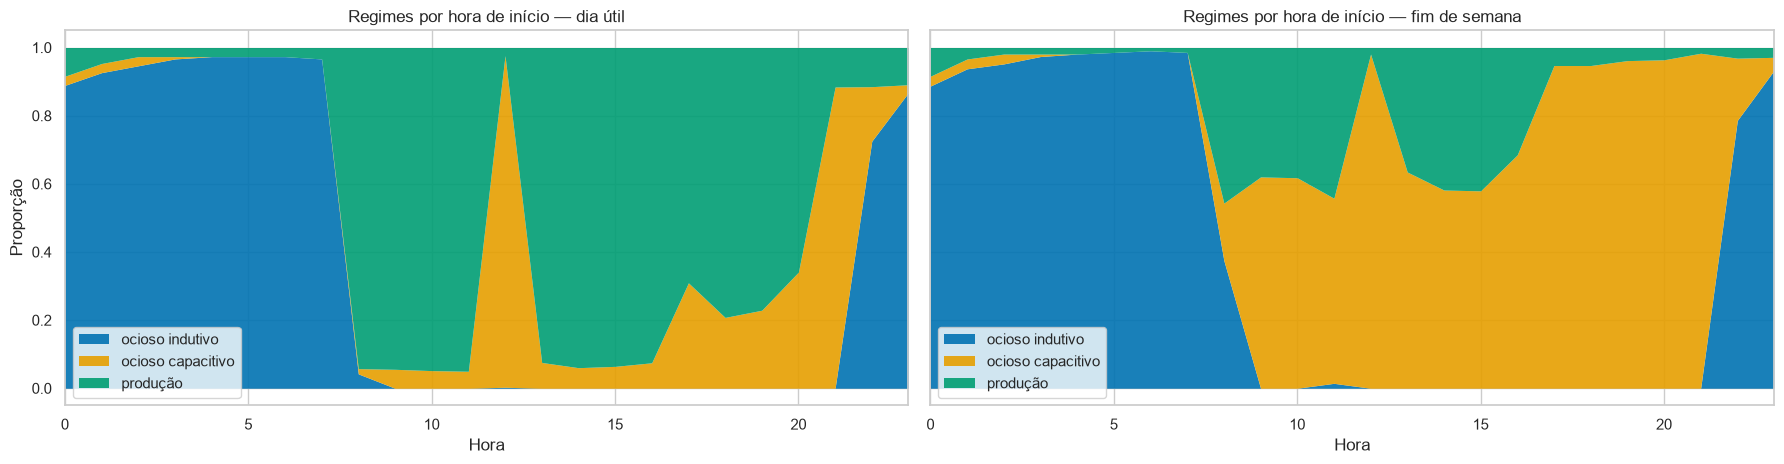

In [3]:
shares = (
    results.assign(dia=np.where(results[pp.WEEK_STATUS] == "Weekend", "fim de semana", "dia útil"))
    .groupby(["dia", "hora"])["regime_name"]
    .value_counts(normalize=True)
    .rename("proporcao")
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), sharey=True)
for ax, day_type in zip(axes, ["dia útil", "fim de semana"]):
    table = shares[shares["dia"] == day_type].pivot(
        index="hora", columns="regime_name", values="proporcao"
    )
    table = table.reindex(columns=md.REGIME_NAMES).fillna(0)
    table.plot.area(
        ax=ax, color=[REGIME_COLORS[name] for name in table.columns], linewidth=0, alpha=0.9
    )
    ax.set(
        title=f"Regimes por hora de início — {day_type}",
        xlabel="Hora",
        ylabel="Proporção",
        xlim=(0, 23),
    )
    ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "29_regimes_dia_util_fim_de_semana.png")
plt.show()

In [4]:
episode_id = (results["regime"] != results["regime"].shift()).cumsum()
episodes = (
    results.groupby(episode_id)
    .agg(regime=("regime_name", "first"), leituras=("regime", "size"), inicio=("inicio", "first"))
    .reset_index(drop=True)
)
episodes["horas"] = episodes["leituras"] / 4
episodes["anterior"] = episodes["regime"].shift(1)
episodes["seguinte"] = episodes["regime"].shift(-1)

durations = episodes.groupby("regime")["horas"].describe(percentiles=[0.5, 0.9])[
    ["count", "50%", "90%", "max"]
]
durations.columns = ["episodios", "mediana_h", "p90_h", "max_h"]
save_table(durations, "revisao_duracao_episodios.csv")
display(durations.reindex(md.REGIME_NAMES))

capacitive = episodes[episodes["regime"] == "ocioso capacitivo"]
context = pd.crosstab(capacitive["anterior"], capacitive["seguinte"])
save_table(context, "revisao_contexto_episodios_capacitivos.csv")
print("Episódios capacitivos: regime anterior (linhas) × seguinte (colunas)")
display(context)
print("Hora de início dos episódios capacitivos (top 6):")
display(capacitive["inicio"].dt.hour.value_counts().head(6).rename("episodios").to_frame())

,episodios,mediana_h,p90_h,max_h
regime,,,,
ocioso indutivo,366.000,9.750,10.500,10.750
ocioso capacitivo,838.000,1.000,6.250,15.250
produção,797.000,4.000,7.500,18.000


Episódios capacitivos: regime anterior (linhas) × seguinte (colunas)


seguinte,ocioso indutivo,produção
anterior,,
ocioso indutivo,64,11
produção,267,496


Hora de início dos episódios capacitivos (top 6):


,episodios
inicio,
12,288
17,151
20,108
21,91
8,74
16,37


### Horário da corrente adiantada

Se a corrente adiantada vem de um banco de capacitores ligado por **horário**, ela deve
depender do relógio e não da carga. O teste usa apenas leituras de **carga baixa**
(< 10 kWh), para comparar a mesma condição elétrica em horários diferentes.

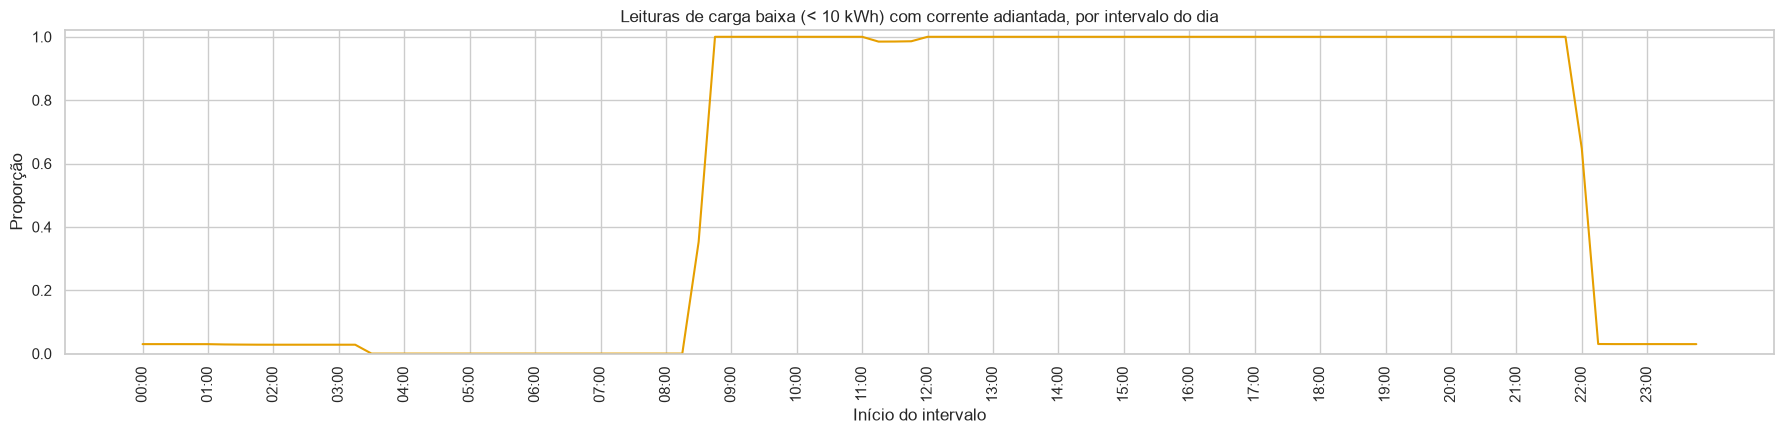

,proporcao_com_corrente_adiantada,leituras_carga_baixa
intervalo,,
08:00–08:15,0.000,70
08:15–08:30,0.000,67
08:30–08:45,0.353,68
08:45–09:00,1.000,66
21:30–21:45,1.000,321
21:45–22:00,1.000,327
22:00–22:15,0.646,328
22:15–22:30,0.030,330


Carga baixa entre 23h e 08h com corrente adiantada: 1.4%


In [5]:
low_load = results[results[pp.USAGE] < LOW_LOAD_KWH].assign(
    corrente_adiantada=lambda f: f[pp.LEADING_KVARH] > LEADING_ON_KVARH
)
leading_by_slot = low_load.groupby("intervalo")["corrente_adiantada"].agg(["mean", "size"])
leading_by_slot.columns = ["proporcao_com_corrente_adiantada", "leituras_carga_baixa"]
save_table(leading_by_slot, "revisao_corrente_adiantada_por_intervalo.csv")

fig, ax = plt.subplots(figsize=(18, 4.5))
ax.plot(
    range(len(leading_by_slot)),
    leading_by_slot["proporcao_com_corrente_adiantada"],
    color=HIGH_CONTRAST_PALETTE[1],
)
ticks = list(range(0, len(leading_by_slot), 4))
ax.set_xticks(ticks, [leading_by_slot.index[i][:5] for i in ticks], rotation=90)
ax.set(
    title="Leituras de carga baixa (< 10 kWh) com corrente adiantada, por intervalo do dia",
    xlabel="Início do intervalo",
    ylabel="Proporção",
    ylim=(0, 1.02),
)
fig.tight_layout()
save_figure(fig, "30_corrente_adiantada_por_horario.png")
plt.show()

window = [
    "08:00–08:15",
    "08:15–08:30",
    "08:30–08:45",
    "08:45–09:00",
    "21:30–21:45",
    "21:45–22:00",
    "22:00–22:15",
    "22:15–22:30",
]
display(leading_by_slot.loc[window])
night = low_load[(low_load["hora"] >= 23) | (low_load["hora"] < 8)]["corrente_adiantada"].mean()
print(f"Carga baixa entre 23h e 08h com corrente adiantada: {night:.1%}")

### Leitura para a validação

- **ocioso indutivo** é um bloco noturno longo e regular (mediana de ~10 h por episódio),
  sem corrente adiantada: a planta parada, com magnetização de transformadores e motores
  em vazio puxando reativo atrasado.
- **ocioso capacitivo** aparece em episódios curtos **entre dois blocos de produção**
  (pausas, com pico às 12h nos dias úteis — compatível com almoço), no **fim do expediente**
  antes do bloco noturno e durante boa parte do dia nos fins de semana.
- A corrente adiantada em carga baixa **segue o relógio**: começa por volta das 08:30,
  fica presente até ~22:00 e praticamente não aparece à noite com a mesma carga. Isso é
  compatível com um **banco de capacitores acionado por horário**, e não pela carga.

**Perguntas para quem conhece a planta**

1. Existe pausa programada por volta das 12:00–13:00 nos dias úteis?
2. O banco de capacitores (ou outra compensação de reativos) é ligado por temporizador,
   entre aproximadamente 08:30 e 22:00? Ele fica ligado nos fins de semana?
3. A planta trabalha parcialmente aos sábados e domingos durante o dia?
4. Os nomes "ocioso indutivo", "ocioso capacitivo" e "produção" fazem sentido, ou há
   termos internos melhores (ex.: "parada noturna", "standby compensado")?

## 3. Triagem dos alertas de anomalia

Cada alerta recebe duas marcações objetivas:

- **fronteira:** o regime da leitura difere do regime da leitura anterior ou da seguinte.
  Uma leitura de 15 minutos que cobre a troca de estado mistura os dois e tende a parecer
  incomum;
- **recorrente:** o mesmo dia da semana e intervalo gerou alerta em pelo menos 3 semanas
  distintas no ano.

Combinando as duas, sai uma categoria sugerida e uma prioridade de revisão.

In [6]:
# Mesma regra do modelo: só passos consecutivos de 15 min; as pontas do ano não contam.
results["fronteira"] = md.regime_boundaries(results["regime"], results["timestamp"])
# Revisão retrospectiva dos alertas sem filtro, inclusive os suprimidos na v1.1.
RAW_FLAG = "is_anomaly_raw" if "is_anomaly_raw" in results.columns else "is_anomaly"
alerts = results[results[RAW_FLAG]].copy()
alerts["semanas_no_padrao"] = alerts.groupby([pp.DAY_OF_WEEK, "intervalo"])["semana"].transform(
    "nunique"
)
alerts["recorrente"] = alerts["semanas_no_padrao"] >= RECURRENCE_MIN_WEEKS

CATEGORIES = {
    (True, True): ("transição programada", 4),
    (True, False): ("transição pontual", 3),
    (False, True): ("padrão recorrente", 2),
    (False, False): ("isolado — investigar", 1),
}
alerts["categoria_sugerida"] = [
    CATEGORIES[(f, r)][0] for f, r in zip(alerts["fronteira"], alerts["recorrente"])
]
alerts["prioridade"] = [
    CATEGORIES[(f, r)][1] for f, r in zip(alerts["fronteira"], alerts["recorrente"])
]

base_rate = results["fronteira"].mean()
print(
    f"Leituras em fronteira: {base_rate:.1%} do total · {alerts['fronteira'].mean():.1%} dos alertas"
)
for split_name in pp.SPLIT_NAMES:
    subset = alerts[alerts[pp.SPLIT_COLUMN] == split_name]
    print(
        f"  {split_name:>10}: {len(subset):>3} alertas, {subset['fronteira'].mean():.1%} em fronteira"
    )

summary = (
    alerts.groupby(["prioridade", "categoria_sugerida"])
    .size()
    .rename("alertas")
    .to_frame()
    .assign(percentual=lambda f: 100 * f["alertas"] / f["alertas"].sum())
)
save_table(summary, "revisao_resumo_categorias.csv")
display(summary)

Leituras em fronteira: 11.1% do total · 81.3% dos alertas
       train: 471 alertas, 79.6% em fronteira
  validation:  59 alertas, 88.1% em fronteira
        test:  49 alertas, 89.8% em fronteira


,,alertas,percentual
prioridade,categoria_sugerida,,
1,isolado — investigar,38,6.563
2,padrão recorrente,70,12.090
3,transição pontual,50,8.636
4,transição programada,421,72.712


!!! note "Alertas do treino"
    O Isolation Forest foi ajustado no treino, então os escores de jan–ago são dentro da
    amostra e a taxa ali (~2%) não é comparável à da validação e do teste (~1%). Os
    alertas do treino entram na triagem porque ajudam a revelar padrões recorrentes, mas
    a coluna `split` permite separá-los.

,,alertas,semanas,meses,em_fronteira
day_of_week,intervalo,,,,
Sunday,22:00–22:15,32,32,8,1.000
Saturday,22:00–22:15,30,30,8,1.000
Tuesday,12:00–12:15,29,29,10,1.000
Thursday,12:00–12:15,28,28,10,1.000
Saturday,13:00–13:15,25,25,12,1.000
Wednesday,12:00–12:15,23,23,9,1.000
Monday,12:00–12:15,22,22,9,1.000
Friday,12:00–12:15,20,20,11,1.000
Saturday,11:45–12:00,17,17,10,0.941


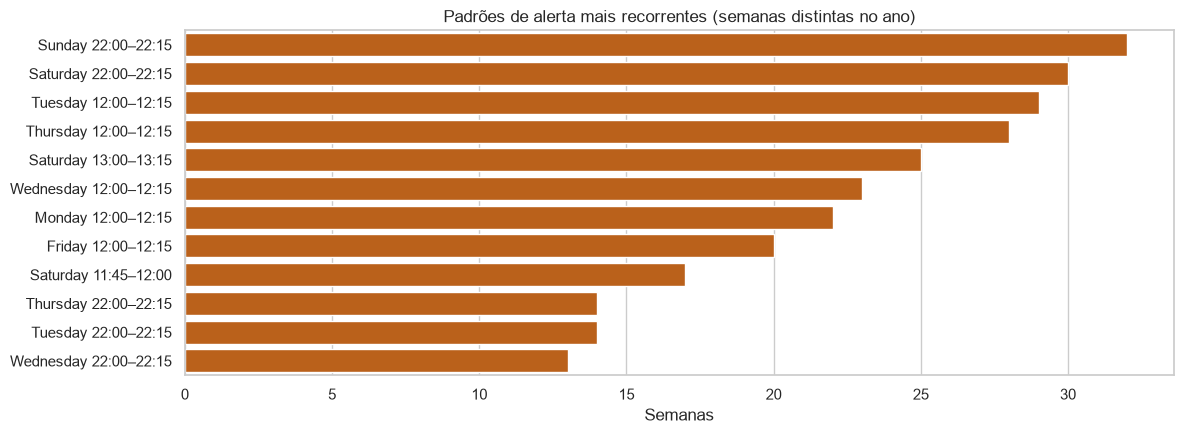

In [7]:
recurring_patterns = (
    alerts[alerts["recorrente"]]
    .groupby([pp.DAY_OF_WEEK, "intervalo"])
    .agg(
        alertas=("semana", "size"),
        semanas=("semana", "nunique"),
        meses=("inicio", lambda s: s.dt.month.nunique()),
        em_fronteira=("fronteira", "mean"),
    )
    .sort_values("semanas", ascending=False)
)
save_table(recurring_patterns, "revisao_padroes_recorrentes.csv")
display(recurring_patterns.head(12))

fig, ax = plt.subplots(figsize=(12, 4.5))
top = recurring_patterns.head(12).reset_index()
top["padrao"] = top[pp.DAY_OF_WEEK] + " " + top["intervalo"]
sns.barplot(data=top, y="padrao", x="semanas", color=HIGH_CONTRAST_PALETTE[3], ax=ax)
ax.set(
    title="Padrões de alerta mais recorrentes (semanas distintas no ano)",
    xlabel="Semanas",
    ylabel="",
)
fig.tight_layout()
save_figure(fig, "31_padroes_alerta_recorrentes.png")
plt.show()

In [8]:
profile_columns = [*pp.ENERGY_COLUMNS, *pp.POWER_FACTOR_COLUMNS]
for day, slots, label in [
    (
        "Sunday",
        ["21:30–21:45", "21:45–22:00", "22:00–22:15", "22:15–22:30"],
        "domingo, desligamento noturno",
    ),
    (
        "Tuesday",
        ["11:30–11:45", "11:45–12:00", "12:00–12:15", "12:15–12:30"],
        "terça, início da pausa",
    ),
]:
    view = results[(results[pp.DAY_OF_WEEK] == day) & results["intervalo"].isin(slots)]
    print(f"Mediana por intervalo — {label}:")
    display(view.groupby("intervalo")[[*profile_columns, "anomaly_score"]].median().reindex(slots))

Mediana por intervalo — domingo, desligamento noturno:


,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
intervalo,,,,,,
21:30–21:45,3.205,0.000,16.380,100.000,20.215,0.517
21:45–22:00,3.350,0.000,16.740,100.000,20.010,0.526
22:00–22:15,3.260,1.730,8.910,89.145,36.665,0.631
22:15–22:30,3.005,4.465,0.000,56.375,100.000,0.525


Mediana por intervalo — terça, início da pausa:


,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
intervalo,,,,,,
11:30–11:45,63.270,42.765,0.000,85.560,100.000,0.458
11:45–12:00,66.400,41.310,0.000,85.630,100.000,0.472
12:00–12:15,9.850,1.940,17.390,98.420,54.245,0.635
12:15–12:30,5.685,0.000,21.290,100.000,26.400,0.535


A leitura de fronteira fica literalmente **no meio** dos dois estados (consumo e reativos
intermediários entre o antes e o depois). É um artefato da resolução de 15 minutos, não
uma falha.

In [9]:
isolated = alerts[alerts["categoria_sugerida"] == "isolado — investigar"]
isolated_view = isolated.sort_values("anomaly_score", ascending=False)[
    [
        pp.TIMESTAMP_COLUMN,
        pp.DAY_OF_WEEK,
        "intervalo",
        pp.SPLIT_COLUMN,
        "regime_name",
        *profile_columns,
        "anomaly_score",
    ]
]
print(f"Alertas isolados (prioridade 1): {len(isolated)}")
display(isolated_view.head(15))

Alertas isolados (prioridade 1): 38


,timestamp,day_of_week,intervalo,split,regime_name,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
1293,2018-01-14 11:30:00,Sunday,11:15–11:30,train,ocioso capacitivo,12.960,0.940,5.150,99.740,92.930,0.644
13572,2018-05-22 09:15:00,Tuesday,09:00–09:15,train,ocioso capacitivo,24.700,0.000,11.340,100.000,90.880,0.638
13573,2018-05-22 09:30:00,Tuesday,09:15–09:30,train,ocioso capacitivo,24.770,0.000,11.270,100.000,91.020,0.636
19307,2018-07-21 03:00:00,Saturday,02:45–03:00,train,ocioso capacitivo,3.350,0.000,4.250,100.000,61.900,0.636
18923,2018-07-17 03:00:00,Tuesday,02:45–03:00,train,ocioso capacitivo,3.490,0.000,3.850,100.000,67.160,0.634
13575,2018-05-22 10:00:00,Tuesday,09:45–10:00,train,ocioso capacitivo,25.520,0.110,8.780,100.000,94.560,0.634
19306,2018-07-21 02:45:00,Saturday,02:30–02:45,train,ocioso capacitivo,3.780,0.000,4.460,100.000,64.660,0.634
19401,2018-07-22 02:30:00,Sunday,02:15–02:30,train,ocioso capacitivo,3.310,0.000,4.500,100.000,59.250,0.633
22125,2018-08-19 11:30:00,Sunday,11:15–11:30,train,ocioso capacitivo,3.920,0.220,3.740,99.840,72.350,0.632
18921,2018-07-17 02:30:00,Tuesday,02:15–02:30,train,ocioso capacitivo,2.950,0.000,3.560,100.000,63.810,0.631


### Planilha de triagem

`artifacts/tables/revisao_alertas_triagem.csv` lista **todos** os alertas, ordenados por
prioridade (1 = revisar primeiro) e escore. A coluna `parecer_operacao` está vazia para a
operação preencher com uma destas opções:

- `rotina` — evento programado, conhecido (não deve gerar alarme);
- `transicao` — mudança normal de estado (não deve gerar alarme);
- `falha` — problema real de equipamento ou processo;
- `investigar` — desconhecido, merece apuração;
- `dado` — erro de medição ou registro.

Com os pareceres preenchidos, será possível medir pela primeira vez a **precisão** do
detector e avaliar se o filtro já aplicado na v1.1 deve continuar ativo. A recorrência usa o ano inteiro e é retrospectiva; em operação, deve usar apenas informações disponíveis até o alerta.

In [10]:
review_columns = [
    "prioridade",
    "categoria_sugerida",
    pp.TIMESTAMP_COLUMN,
    "intervalo",
    pp.DAY_OF_WEEK,
    pp.SPLIT_COLUMN,
    "regime_name",
    "fronteira",
    "recorrente",
    "semanas_no_padrao",
    *profile_columns,
    "anomaly_score",
]
review = alerts.sort_values(["prioridade", "anomaly_score"], ascending=[True, False])[
    review_columns
].copy()
review["parecer_operacao"] = ""
review["observacao"] = ""
save_table(review, "revisao_alertas_triagem.csv", index=False)
print(f"Planilha salva com {len(review)} alertas.")
display(review["categoria_sugerida"].value_counts().rename("alertas").to_frame())

Planilha salva com 579 alertas.


,alertas
categoria_sugerida,
transição programada,421
padrão recorrente,70
transição pontual,50
isolado — investigar,38


## 4. Resumo para a reunião

**Decisões (item 1).** As nove decisões estão registradas na seção 1, com evidência e
impacto. Nenhuma depende de dados adicionais para ser aprovada; D3 (calendário fora) e
D8 (taxa de 1%) são as que mais mudam a leitura dos resultados.

**Regimes (item 2).** As evidências sustentam os três nomes: o bloco noturno indutivo é
regular, o capacitivo aparece em pausas e no fim do expediente, e a corrente adiantada
segue um horário fixo. Faltam as respostas da planta às quatro perguntas da seção 2.

**Alertas (item 3).** A grande maioria dos alertas cai em trocas de regime, que ocupam
uma fração pequena das leituras — o detector está sinalizando sobretudo **transições**.
Os alertas isolados, fora de fronteira e sem recorrência, são os candidatos reais e estão
no topo da planilha de triagem.

**Recomendação técnica (para decidir após a triagem):** se a operação confirmar que
transições não interessam, filtrar alertas em fronteira de regime antes de alarmar, ou
reajustar o limiar só com leituras fora de fronteira.

## 5. Experimentos de melhoria: supervisionado e não supervisionado

A comparação supervisionada acrescenta árvores extremamente aleatórias e KNN ponderado, escolhendo pela validação. As comparações de K-Means avaliam a retirada do fator de potência adiantado, correlacionado à energia reativa adiantada; silhuetas em espaços diferentes são apenas indicativas. Para o Isolation Forest, comparamos a estabilidade dos 1% maiores escores entre sementes, sem afirmar precisão de falha. Os modelos são ajustados só no treino e não substituem artefatos publicados.

A EDA e decisões anteriores já consultaram todo o ano, inclusive o teste. Os resultados são retrospectivos, e sucessivas experiências aumentam o risco de adaptação aos mesmos períodos. Uma melhoria operacional precisa de validação em dados posteriores e parecer humano; compare também o custo e os casos omitidos pelo filtro.

In [11]:
from regime_anomaly.data import load_data
from regime_anomaly.experiments import supervised_comparison, unsupervised_sensitivity
experiment_frame, _ = pp.prepare_frame(load_data())
experiment_splits = {name: experiment_frame[experiment_frame[pp.SPLIT_COLUMN] == name].reset_index(drop=True) for name in pp.SPLIT_NAMES}
baseline_candidates, baseline_outcome, _, _ = supervised_comparison(experiment_splits)
supervised_candidates, supervised_outcome, supervised_report, supervised_confusion = supervised_comparison(experiment_splits, alternatives=True)
print('Candidatos supervisionados — seleção por F1 macro na validação')
display(supervised_candidates.round(4))
print('Comparação no teste histórico; não é teste independente')
print('KNN de referência, selecionado na validação:')
display(baseline_outcome.round(4))
print('Melhor candidato ampliado, selecionado na validação:')
display(supervised_outcome.round(4))
display(supervised_report.round(4))
display(supervised_confusion)
regime_sensitivity, anomaly_sensitivity = unsupervised_sensitivity(experiment_splits)
print('Regimes — geometria e estabilidade na validação')
display(regime_sensitivity.round(4))
print('Anomalias — estabilidade entre sementes na validação; sem medida de precisão')
display(anomaly_sensitivity.round(4))

Candidatos supervisionados — seleção por F1 macro na validação


,features,modelo,f1_macro_validacao,acuracia_balanceada_validacao
0,regime_with_calendar,extra_trees,0.954,0.952
1,regime_with_calendar,knn_31_distance,0.920,0.922
2,regime_with_calendar,knn_15,0.919,0.920
3,regime_with_calendar,knn_31,0.914,0.917
4,regime_with_calendar,knn_5,0.906,0.907
5,regime,extra_trees,0.684,0.723
6,regime,knn_31,0.678,0.713
7,regime,knn_31_distance,0.674,0.699
8,regime,knn_15,0.665,0.690
9,regime,knn_5,0.648,0.662


Comparação no teste histórico; não é teste independente
KNN de referência, selecionado na validação:


,acuracia,acuracia_balanceada,f1_macro
modelo,,,
selecionado,0.699,0.593,0.593
classe_majoritaria,0.531,0.333,0.231


Melhor candidato ampliado, selecionado na validação:


,acuracia,acuracia_balanceada,f1_macro
modelo,,,
selecionado,0.704,0.593,0.593
classe_majoritaria,0.531,0.333,0.231


... (2 outputs left out)

Regimes — geometria e estabilidade na validação


,silhueta,menor_grupo,ari_sementes_medio
configuracao,,,
cinco_variaveis,0.821,0.213,1.000
sem_fp_adiantado,0.827,0.225,1.000


Anomalias — estabilidade entre sementes na validação; sem medida de precisão


,taxa_validacao,jaccard_sementes_medio
max_samples,,
256,0.010,0.762
1024,0.010,0.674


## 6. Cenários controlados de outliers

A mesma leitura histórica de validação é alterada em consumo, energia reativa e fator de potência, preservando as leituras vizinhas. A tabela compara o escore, a variação em relação à referência, o alerta bruto e o efeito do filtro em fronteiras. As alterações são sintéticas e podem não representar condições físicas possíveis: a ausência ou presença de alerta não comprova acerto. Para medir detecção real, é necessário obter pareceres sobre alertas e não alertas, com dados independentes.

In [ ]:
import joblib
from regime_anomaly.config import MODELS_DIR
from regime_anomaly.scenarios import anomaly_scenarios
scenario_model = joblib.load(MODELS_DIR / 'final_model.joblib')
scenario_results = anomaly_scenarios(scenario_model, experiment_frame)
print(f'Limiar do modelo: {scenario_model.anomaly_threshold:.4f}')
display(scenario_results.round(4))